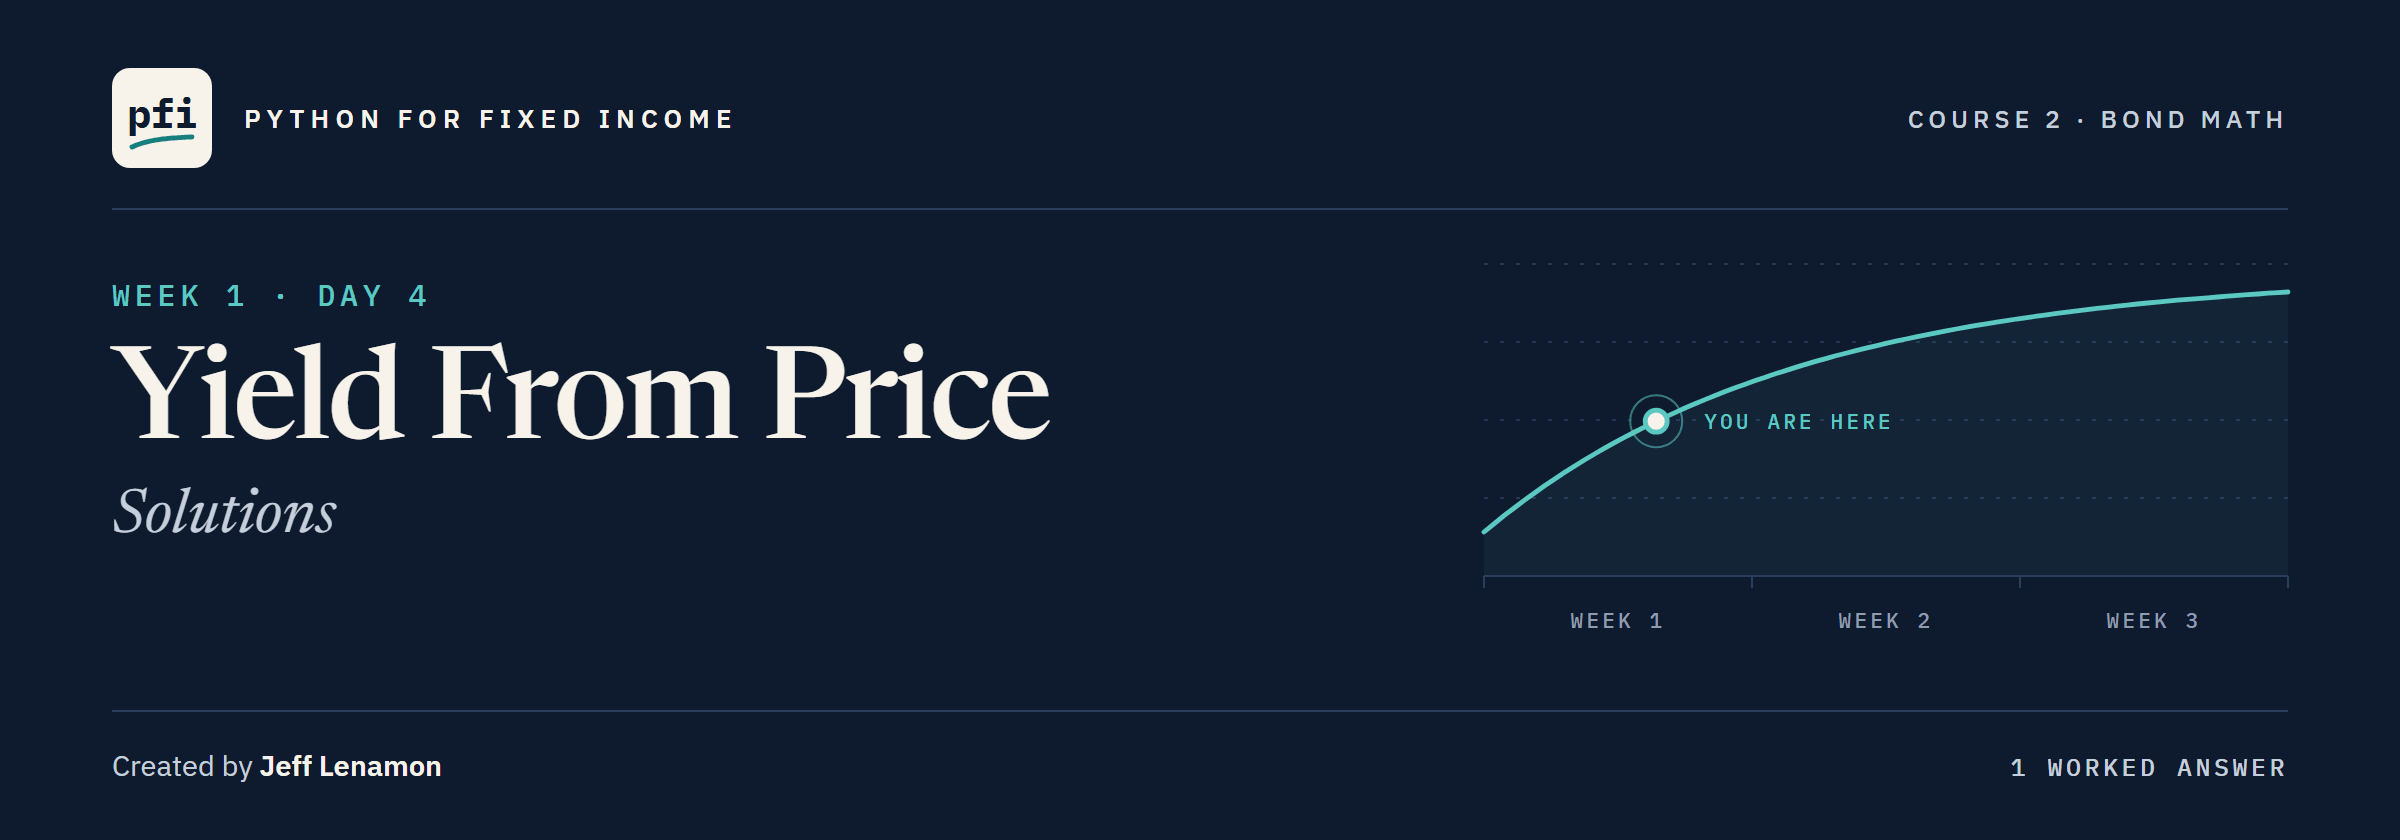

# Yield From Price: Solutions

Week 1, Day 4. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week1/day4/04_yield_from_price_solutions.ipynb)

## Exercises

Run the next three cells first: the work folder with the module as the notebook ends, the imports and the bonds, and `check`.

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/course02_bond_math/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}start_of_day/start_day.py
from start_day import start_day

# a new work folder: the Excel files, and the module and its tests as notebook 04 ends.
# To start the day again, restart the kernel and run all cells.
work = start_day(4, after=4)

Work folder pfi_course2_04_k4w7q2xr: 2 data files, the module as notebook 04 left it, 4 commits


In [2]:
import importlib

import pandas as pd

import bondmath

tvm = pd.read_csv('bondmath_excel_reference_tvm.csv', index_col='case_id')
rate_rows = tvm[tvm['function'] == 'RATE']
exercise_bonds = pd.DataFrame({
    'issuer': ['Ostrevale Telecom', 'Tarnwick Utilities', 'Osmere Chemicals', 'Calderby Retail'],
    'ticker': ['OSTV', 'TRNW', 'OSMC', 'CLDB'],
    'coupon_pct': [5.625, 4.375, 5.0, 8.25],
    'years': [4, 2, 6, 8],
    'quote': [99.5, 100.25, 98.375, 97.625],
})

In [3]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

### Exercise 1

In [4]:
terms = zip(exercise_bonds['coupon_pct'], exercise_bonds['quote'], exercise_bonds['years'])
exercise_bonds['yield_pct'] = [bondmath.yield_from_price(c, p, t) for c, p, t in terms]
ex1_osmere = exercise_bonds.loc[2, 'yield_pct']
# idxmax gives the row label of the largest yield
ex1_highest = exercise_bonds.loc[exercise_bonds['yield_pct'].idxmax(), 'ticker']
check('Exercise 1 Osmere yield', ex1_osmere, 5.319909556762923)
check('Exercise 1 highest yield', ex1_highest, 'CLDB')

Exercise 1 Osmere yield: correct
Exercise 1 highest yield: correct


Calderby, 8.25 coupon at 97.625, yields 8.6677, Excel's `RATE` row `tvm_rate_18`; Tarnwick, the one quote above 100, yields 4.2433, under its 4.375 coupon.

### Exercise 2

In [5]:
halvering_before = bondmath.yield_from_price(7.5, 97.75, 10)
pellwick_before = bondmath.yield_from_price(4.75, 100.875, 3)
# a change in yield, in basis points: 100 to a percent
ex2_halvering_bp = (bondmath.yield_from_price(7.5, 98.75, 10) - halvering_before) * 100
ex2_pellwick_bp = (bondmath.yield_from_price(4.75, 101.875, 3) - pellwick_before) * 100
ex2_larger = 'PLWK' if abs(ex2_pellwick_bp) > abs(ex2_halvering_bp) else 'HLVF'
check('Exercise 2 Halvering change', ex2_halvering_bp, -14.724150213623943)
check('Exercise 2 Pellwick change', ex2_pellwick_bp, -35.56528486387833)
check('Exercise 2 larger move', ex2_larger, 'PLWK')

Exercise 2 Halvering change: correct
Exercise 2 Pellwick change: correct
Exercise 2 larger move: correct


The same point of price moves Pellwick's 3-year yield 35.6 bp and Halvering's 10-year only 14.7: a point spread over fewer years is more yield each year.

### Exercise 3

In [6]:
%%writefile -a bondmath.py


def yield_change_bp(old_yield_pct: float, new_yield_pct: float) -> float:
    """The change from one yield to another, in basis points.

    Units: both yields in percent a year; the result in basis points, 100 to a percent.
    Convention: new minus old, so a rise is positive and a fall negative.
    Excel: =(B1-A1)*100, the old yield in A1 and the new in B1.
    """
    # a percent is 100 basis points
    return (new_yield_pct - old_yield_pct) * 100

Appending to bondmath.py


In [7]:
%%writefile -a test_bondmath.py


def test_yield_change_bp_cases():
    # hand cases: 5.40 to 5.50 is a rise of 10 bp; 6.00 to 5.75 is a fall of 25 bp
    assert bondmath.yield_change_bp(5.4, 5.5) == pytest.approx(10.0)
    assert bondmath.yield_change_bp(6.0, 5.75) == pytest.approx(-25.0)
    # Excel's RATE and YIELD on the same eight quotes: the last eight RATE rows and the YIELD rows
    for rate_row, yield_row in zip(tvm_rows("RATE")[10:], tvm_rows("YIELD")):
        change = bondmath.yield_change_bp(float(rate_row["excel_value"]) * 100,
                                          float(yield_row["excel_value"]) * 100)
        assert abs(change) < 0.0001, yield_row["case_id"]

Appending to test_bondmath.py


In [8]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

............                                                             [100%]
12 passed in 0.50s



In [9]:
importlib.reload(bondmath)
quorvane_yield_pct = bondmath.yield_from_price(5.25, 99.125, 5)
ex3_change = bondmath.yield_change_bp(5.4, quorvane_yield_pct)
check('Exercise 3 Quorvane yield change', ex3_change, 5.229650329247271)

Exercise 3 Quorvane yield change: correct


`12 passed`, and Quorvane's yield is 5.2297 bp above its issue yield.
In Excel, `YIELD` times 100 in B1 and 5.4 in A1 make `=(B1-A1)*100` 5.229650329569946, 3.2e-10 bp from yours.
`tvm_rows("RATE")[10:]` slices off the first ten rows, so the eight left are the quotes the `YIELD` rows hold, in the same order.

### Exercise 4: AI check

The bug: the code searched the rate per period and returned it without multiplying back by the frequency, so Quorvane came back 2.7261, half its 5.4523.
The test stopped on the first row, `tvm_rate_01`: 2.821133 against 5.642266.
The fix: the docstring promises an annual yield, so return the rate per period times the frequency.

In [10]:
def assistant_yield_from_price(coupon_pct, price, years, frequency=2):
    """Yield of a bullet bond on a coupon date, from its price, by bisection.

    Units: coupon_pct in percent a year, price per 100 of face, years in years; the result is in
    percent. Convention: the yield, compounded `frequency` times a year, at which price_from_yield
    equals price. Raises ValueError if the price is outside the prices at -5 and 100 percent.
    """
    # search the rate per period, in percent: the annual bracket divided by the frequency
    low_pct, high_pct = -5.0 / frequency, 100.0 / frequency
    highest_price = bondmath.price_from_yield(coupon_pct, low_pct * frequency, years, frequency)
    lowest_price = bondmath.price_from_yield(coupon_pct, high_pct * frequency, years, frequency)
    if not lowest_price <= price <= highest_price:
        raise ValueError(f'price {price} is outside {lowest_price:.6f} to {highest_price:.6f}')
    while high_pct - low_pct > 1e-10:
        mid_pct = (low_pct + high_pct) / 2
        # price_from_yield takes the annual yield: the rate per period times the frequency
        if bondmath.price_from_yield(coupon_pct, mid_pct * frequency, years, frequency) > price:
            low_pct = mid_pct
        else:
            high_pct = mid_pct
    # the fix: the docstring promises a yield a year, so the rate per period times the frequency
    return (low_pct + high_pct) / 2 * frequency

In [11]:
for case, coupon, quote, years, frequency, excel in zip(
        rate_rows.index, rate_rows['coupon_pct'], rate_rows['price'], rate_rows['years'],
        rate_rows['frequency'], rate_rows['excel_value']):
    result = assistant_yield_from_price(coupon, quote, years, frequency)
    # RATE times the frequency is a decimal a year; the docstring promises percent
    assert abs(result - excel * 100) < 1e-6, f'{case}: {result:.6f} against {excel * 100:.6f}'
print(f'All {len(rate_rows)} RATE rows match Excel')

All 18 RATE rows match Excel


In [12]:
ex4_quorvane = assistant_yield_from_price(5.25, 99.125, 5)
ex4_rows = len(rate_rows)
check('Exercise 4 Quorvane yield', ex4_quorvane, 5.452296503292473)
check('Exercise 4 rows checked', ex4_rows, 18)

Exercise 4 Quorvane yield: correct
Exercise 4 rows checked: correct


[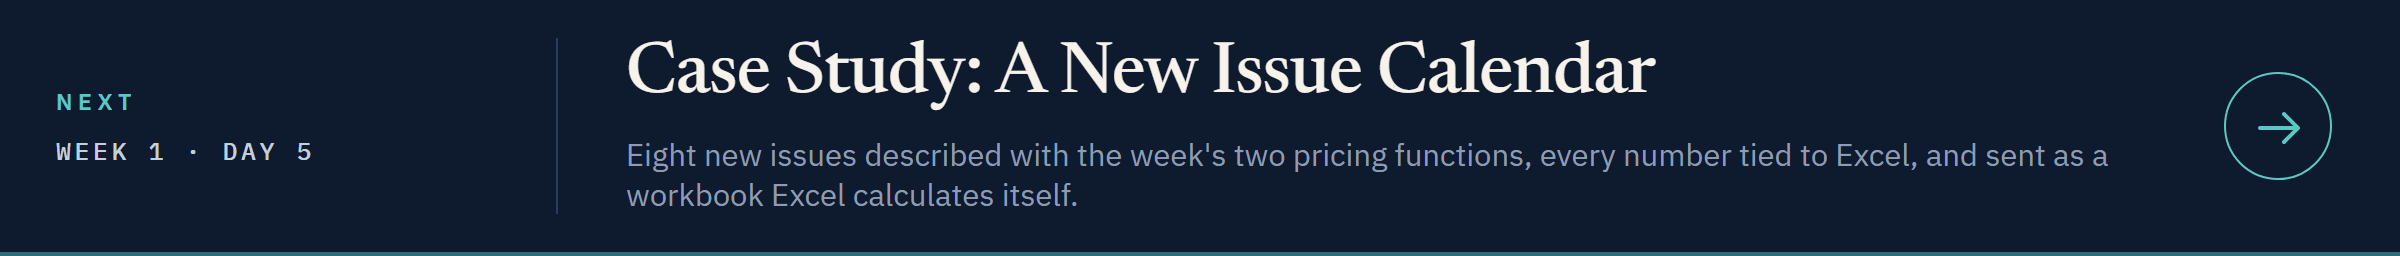](../day5/05_case_study_a_new_issue_calendar.ipynb)

[Open Day 5 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week1/day5/05_case_study_a_new_issue_calendar.ipynb)